<a href="https://colab.research.google.com/github/Maruf0275/Machine-Learning-CIT/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder, RobustScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/drive/MyDrive/Machine Learning(CIT)/Datasets/weight-height.csv')

In [3]:
df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [4]:
df.shape

(10000, 3)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  object 
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), object(1)
memory usage: 234.5+ KB


In [6]:
df.isnull().sum()

,0
Gender,0
Height,0
Weight,0


In [7]:
x = df[['Height','Weight']]
y = df[['Gender']]

In [8]:
x.head()

,Height,Weight
0,73.847017,241.893563
1,68.781904,162.310473
2,74.110105,212.740856
3,71.730978,220.042470
4,69.881796,206.349801


In [9]:
y.head()

,Gender
0,Male
1,Male
2,Male
3,Male
4,Male


In [12]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
logit = LogisticRegression()

In [14]:
model = logit.fit(xtrain,ytrain)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [15]:
model.score(xtrain,ytrain)

0.91825

In [16]:
model.score(xtest,ytest)

0.9245

In [18]:
model.predict([[72.43, 200]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['Male'], dtype=object)

In [19]:
xx = df[['Height','Weight']]
yy = df[['Gender']]

In [20]:
xx.head()

,Height,Weight
0,73.847017,241.893563
1,68.781904,162.310473
2,74.110105,212.740856
3,71.730978,220.042470
4,69.881796,206.349801


In [21]:
yy.head()

,Gender
0,Male
1,Male
2,Male
3,Male
4,Male


In [23]:
le = LabelEncoder()
rbs = RobustScaler()

In [24]:
xx['Height'] = rbs.fit_transform(xx[['Height']])
xx['Weight'] = rbs.fit_transform(xx[['Weight']])

/tmp/ipykernel_1421/2215035074.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  xx['Height'] = rbs.fit_transform(xx[['Height']])
/tmp/ipykernel_1421/2215035074.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  xx['Weight'] = rbs.fit_transform(xx[['Weight']])


In [25]:
xx.head()

,Height,Weight
0,1.328175,1.571145
1,0.434643,0.021373
2,1.374586,1.003436
3,0.954886,1.145625
4,0.628674,0.878979


In [26]:
yy['Gender'] = le.fit_transform(yy['Gender'])

/tmp/ipykernel_1421/2177223160.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  yy['Gender'] = le.fit_transform(yy['Gender'])


In [27]:
yy.head()

,Gender
0,1
1,1
2,1
3,1
4,1


In [28]:
x_train,x_test,y_train,y_test = train_test_split(xx,yy,test_size=0.2,random_state=42)

In [30]:
logis = LogisticRegression(verbose=2)

In [31]:
model1 = logis.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished


In [32]:
model1.score(x_train,y_train)

0.918375

In [33]:
model1.score(x_test,y_test)

0.924

In [36]:
y_pred = model1.predict(x_test)

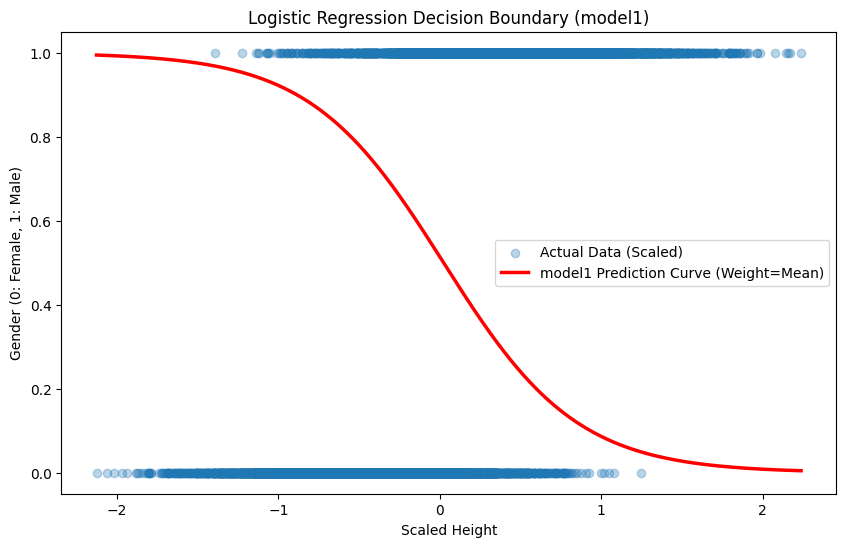

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate a range of scaled heights
height_range = np.linspace(xx['Height'].min(), xx['Height'].max(), 1000)

# 2. To predict with model1, we must provide both features: 'Height' and 'Weight'
# We will hold 'Weight' constant at its mean value
mean_weight = xx['Weight'].mean()

# Create a DataFrame for predictions matching the training features
prediction_grid = pd.DataFrame({
    'Height': height_range,
    'Weight': [mean_weight] * len(height_range)
})

# 3. Predict the probability of being Male (class 1)
# model1 predicts on scaled input, returning [prob_female, prob_male]
probs = model1.predict_proba(prediction_grid)[:, 1]

# 4. Plot the results using scaled Height vs Gender
plt.figure(figsize=(10, 6))

# Plot the actual scaled data points
plt.scatter(xx['Height'], yy['Gender'], color='#1f77b4', alpha=0.3, label='Actual Data (Scaled)')

# Plot the sigmoid probability curve generated by model1
plt.plot(height_range, probs, color='red', linewidth=2.5, label='model1 Prediction Curve (Weight=Mean)')

plt.xlabel('Scaled Height')
plt.ylabel('Gender (0: Female, 1: Male)')
plt.title('Logistic Regression Decision Boundary (model1)')
plt.legend()
plt.grid(False)
plt.show()